**Install and import libraries**

In [ ]:
!pip install -q nltk scikit-learn pandas matplotlib seaborn

import nltk
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("Libraries imported successfully.")

Libraries imported successfully.


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


**Create labelled corpus**

In [ ]:
data = {
    "symptoms": [
        "What are the symptoms of heart disease?",
        "Why do I experience chest discomfort?",
        "What causes shortness of breath?",
        "Why does my heart beat irregularly?",
        "What are signs of a heart attack?",
        "Why do I feel dizzy frequently?",
        "What causes unusual heart palpitations?",
        "Can heart disease cause fatigue?",
        "Why do I feel pain in my chest?",
        "What are common cardiovascular symptoms?"
    ],

    "prevention": [
        "How can I keep my heart healthy?",
        "What foods prevent heart disease?",
        "How much exercise is good for the heart?",
        "How can I reduce cardiovascular risk?",
        "Does walking improve heart health?",
        "How can I maintain healthy cholesterol?",
        "Is yoga beneficial for the heart?",
        "What lifestyle changes protect the heart?",
        "How can I prevent high blood pressure?",
        "Does quitting smoking improve heart health?"
    ],

    "diet": [
        "What should I eat for a healthy heart?",
        "Which foods are rich in omega 3?",
        "Is eating fruits good for the heart?",
        "Should I avoid saturated fats?",
        "What is a heart healthy diet?",
        "Are nuts beneficial for cardiovascular health?",
        "Is too much salt harmful?",
        "Can vegetables reduce heart disease risk?",
        "Is oily food bad for the heart?",
        "What foods help control cholesterol?"
    ],

    "risk_factors": [
        "Does smoking increase heart disease risk?",
        "Can diabetes cause heart problems?",
        "Is high cholesterol dangerous?",
        "Does obesity affect heart health?",
        "Can stress increase blood pressure?",
        "Is family history a risk factor?",
        "Does alcohol affect the heart?",
        "Can physical inactivity cause heart disease?",
        "How does hypertension affect the heart?",
        "Does age increase cardiovascular risk?"
    ],

    "management": [
        "How can I manage high blood pressure?",
        "How often should I check my blood pressure?",
        "How can cholesterol be controlled?",
        "What should heart patients monitor?",
        "How important are regular heart checkups?",
        "Can prescribed medicines control blood pressure?",
        "How can I monitor my heart rate?",
        "What lifestyle changes help heart patients?",
        "Why should I follow my doctor's advice?",
        "How can I manage cardiovascular disease?"
    ]
}

queries = []
labels = []

for intent, sentences in data.items():
    for sentence in sentences:
        queries.append(sentence)
        labels.append(intent)

df = pd.DataFrame({
    "Query": queries,
    "Intent": labels
})

print("Total queries:", len(df))
display(df.head(10))
print("\nIntent distribution:")
print(df["Intent"].value_counts())

Total queries: 50


,Query,Intent
0,What are the symptoms of heart disease?,symptoms
1,Why do I experience chest discomfort?,symptoms
2,What causes shortness of breath?,symptoms
3,Why does my heart beat irregularly?,symptoms
4,What are signs of a heart attack?,symptoms
5,Why do I feel dizzy frequently?,symptoms
6,What causes unusual heart palpitations?,symptoms
7,Can heart disease cause fatigue?,symptoms
8,Why do I feel pain in my chest?,symptoms
9,What are common cardiovascular symptoms?,symptoms



Intent distribution:
Intent
symptoms        10
prevention      10
diet            10
risk_factors    10
management      10
Name: count, dtype: int64


**Hierarchical taxonomy**

In [ ]:
taxonomy = {
    "Heart Health": {
        "Symptoms": [
            "Chest discomfort",
            "Irregular heartbeat"
        ],
        "Prevention": [
            "Physical activity",
            "Lifestyle modification"
        ],
        "Diet and Nutrition": [
            "Healthy foods",
            "Foods to avoid"
        ],
        "Risk Factors": [
            "Modifiable risk factors",
            "Non-modifiable risk factors"
        ],
        "Disease Management": [
            "Blood pressure monitoring",
            "Medical treatment"
        ]
    }
}

def display_taxonomy(taxonomy):
    for main_category, subcategories in taxonomy.items():
        print(main_category)
        for category, subcategories_list in subcategories.items():
            print("  |--", category)
            for subcategory in subcategories_list:
                print("      |--", subcategory)

display_taxonomy(taxonomy)

Heart Health
  |-- Symptoms
      |-- Chest discomfort
      |-- Irregular heartbeat
  |-- Prevention
      |-- Physical activity
      |-- Lifestyle modification
  |-- Diet and Nutrition
      |-- Healthy foods
      |-- Foods to avoid
  |-- Risk Factors
      |-- Modifiable risk factors
      |-- Non-modifiable risk factors
  |-- Disease Management
      |-- Blood pressure monitoring
      |-- Medical treatment


**Domain concepts and relationships**

In [ ]:
concepts = {
    "Heart": "Organ responsible for pumping blood.",
    "Blood Pressure": "Force exerted by blood against artery walls.",
    "Cholesterol": "Fat-like substance present in blood.",
    "Hypertension": "Persistently elevated blood pressure.",
    "Smoking": "Habit that increases cardiovascular risk.",
    "Exercise": "Physical activity supporting cardiovascular health.",
    "Diet": "Food consumption affecting heart health.",
    "Obesity": "Excessive body fat that can increase health risks.",
    "Diabetes": "Condition involving elevated blood glucose.",
    "Heart Disease": "Conditions affecting the heart and blood vessels."
}

relationships = [
    ("Smoking", "increases risk of", "Heart Disease"),
    ("Hypertension", "increases risk of", "Heart Disease"),
    ("Obesity", "increases risk of", "Heart Disease"),
    ("Diabetes", "increases risk of", "Heart Disease"),
    ("Exercise", "helps prevent", "Heart Disease"),
    ("Diet", "influences", "Cholesterol"),
    ("Cholesterol", "affects", "Heart"),
    ("Hypertension", "affects", "Heart"),
    ("Exercise", "helps control", "Blood Pressure"),
    ("Diet", "influences", "Blood Pressure"),
    ("Heart", "pumps", "Blood")
]

print("DOMAIN CONCEPTS:")
for concept, description in concepts.items():
    print(f"{concept}: {description}")

print("\nRELATIONSHIPS:")
for relation in relationships:
    print(" -> ".join(relation))

print("\nTotal concepts:", len(concepts))
print("Total relationships:", len(relationships))

DOMAIN CONCEPTS:
Heart: Organ responsible for pumping blood.
Blood Pressure: Force exerted by blood against artery walls.
Cholesterol: Fat-like substance present in blood.
Hypertension: Persistently elevated blood pressure.
Smoking: Habit that increases cardiovascular risk.
Exercise: Physical activity supporting cardiovascular health.
Diet: Food consumption affecting heart health.
Obesity: Excessive body fat that can increase health risks.
Diabetes: Condition involving elevated blood glucose.
Heart Disease: Conditions affecting the heart and blood vessels.

RELATIONSHIPS:
Smoking -> increases risk of -> Heart Disease
Hypertension -> increases risk of -> Heart Disease
Obesity -> increases risk of -> Heart Disease
Diabetes -> increases risk of -> Heart Disease
Exercise -> helps prevent -> Heart Disease
Diet -> influences -> Cholesterol
Cholesterol -> affects -> Heart
Hypertension -> affects -> Heart
Exercise -> helps control -> Blood Pressure
Diet -> influences -> Blood Pressure
Heart ->

**NLP preprocessing**

In [ ]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)

    tokens = text.split()

    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    return " ".join(tokens)

df["Processed_Query"] = df["Query"].apply(preprocess)

display(df.head(10))

,Query,Intent,Processed_Query
0,What are the symptoms of heart disease?,symptoms,symptom heart disease
1,Why do I experience chest discomfort?,symptoms,experience chest discomfort
2,What causes shortness of breath?,symptoms,cause shortness breath
3,Why does my heart beat irregularly?,symptoms,heart beat irregularly
4,What are signs of a heart attack?,symptoms,sign heart attack
5,Why do I feel dizzy frequently?,symptoms,feel dizzy frequently
6,What causes unusual heart palpitations?,symptoms,cause unusual heart palpitation
7,Can heart disease cause fatigue?,symptoms,heart disease cause fatigue
8,Why do I feel pain in my chest?,symptoms,feel pain chest
9,What are common cardiovascular symptoms?,symptoms,common cardiovascular symptom


**TF-IDF feature extraction**

In [ ]:
vectorizer = TfidfVectorizer()

X = vectorizer.fit_transform(df["Processed_Query"])
y = df["Intent"]

print("TF-IDF matrix shape:", X.shape)
print("\nSample vocabulary:")
print(vectorizer.get_feature_names_out()[:20])

TF-IDF matrix shape: (50, 93)

Sample vocabulary:
['advice' 'affect' 'age' 'alcohol' 'attack' 'avoid' 'bad' 'beat'
 'beneficial' 'blood' 'breath' 'cardiovascular' 'cause' 'change' 'check'
 'checkup' 'chest' 'cholesterol' 'common' 'control']


**Train the classification model**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = MultinomialNB()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model training completed.")
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Model training completed.
Training samples: 40
Testing samples: 10


**Model evaluation**

Accuracy: 0.5

Classification Report:
              precision    recall  f1-score   support

        diet       0.00      0.00      0.00         2
  management       1.00      0.50      0.67         2
  prevention       0.25      0.50      0.33         2
risk_factors       1.00      0.50      0.67         2
    symptoms       0.67      1.00      0.80         2

    accuracy                           0.50        10
   macro avg       0.58      0.50      0.49        10
weighted avg       0.58      0.50      0.49        10



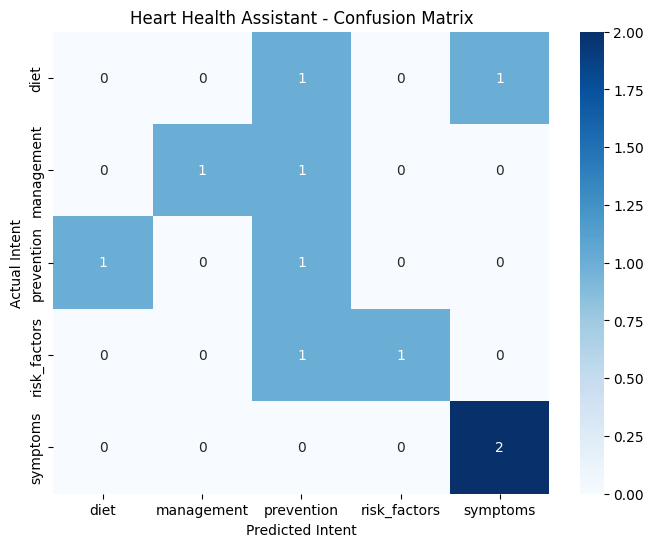

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")
plt.title("Heart Health Assistant - Confusion Matrix")
plt.show()

**Domain-specific knowledge base**

In [ ]:
knowledge_base = {
    "symptoms": """
    Common symptoms of heart-related conditions may include chest discomfort,
    shortness of breath, palpitations, fatigue and dizziness.
    Symptoms can vary between individuals.
    """,

    "prevention": """
    Heart health can be supported through regular physical activity,
    avoiding tobacco, maintaining a healthy weight, managing stress
    and getting regular health checkups.
    """,

    "diet": """
    A heart-healthy diet includes fruits, vegetables, whole grains,
    nuts and foods rich in unsaturated fats.
    Limit excess salt, added sugar and saturated fats.
    """,

    "risk_factors": """
    Cardiovascular risk factors include smoking, hypertension,
    high cholesterol, diabetes, obesity, physical inactivity,
    age and family history.
    """,

    "management": """
    Heart health management includes monitoring blood pressure,
    following prescribed treatment, maintaining healthy habits
    and attending regular medical checkups.
    """
}

print("Knowledge base created.")
for intent in knowledge_base:
    print("-", intent)

Knowledge base created.
- symptoms
- prevention
- diet
- risk_factors
- management


**Rule-based reasoning**

In [ ]:
emergency_keywords = [
    "heart attack",
    "severe chest pain",
    "chest pain",
    "cannot breathe",
    "difficulty breathing",
    "fainting",
    "unconscious"
]

supported_keywords = [
    "heart", "cardiac", "chest", "blood pressure",
    "cholesterol", "exercise", "diet", "smoking",
    "hypertension", "palpitation", "cardiovascular",
    "obesity", "diabetes", "symptom", "attack"
]

def reasoning_engine(query, intent, confidence):

    query_lower = query.lower()

    # Rule 1: Emergency escalation
    if any(word in query_lower for word in emergency_keywords):
        return (
            "EMERGENCY ALERT: Your query mentions a possible "
            "medical emergency. Call emergency services immediately. "
            "In India, call 112 or seek immediate emergency medical care. "
            "Do not wait for an AI response."
        )

    # Rule 2: Unsupported query
    if not any(word in query_lower for word in supported_keywords):
        return (
            "Sorry, this assistant only handles heart health-related "
            "queries. Please ask a question related to heart health."
        )

    # Rule 3: Low confidence
    if confidence < 0.25:
        return (
            "I am not confident enough to classify your query. "
            "Please rephrase your question or consult a healthcare professional."
        )

    # Rule 4: Retrieve relevant information
    if intent in knowledge_base:
        return knowledge_base[intent]

    # Rule 5: Fallback
    return (
        "I could not find relevant information. "
        "Please consult a qualified healthcare professional."
    )

**Integrate the cognitive assistant**

In [ ]:
def heart_health_assistant(query):

    processed_query = preprocess(query)

    query_vector = vectorizer.transform([processed_query])

    probabilities = model.predict_proba(query_vector)[0]

    predicted_intent = model.classes_[np.argmax(probabilities)]

    confidence = np.max(probabilities)

    response = reasoning_engine(
        query,
        predicted_intent,
        confidence
    )

    return {
        "Original Query": query,
        "Processed Query": processed_query,
        "Predicted Intent": predicted_intent,
        "Confidence": round(float(confidence), 4),
        "Response": response
    }


query = "How can I control my cholesterol?"

result = heart_health_assistant(query)

for key, value in result.items():
    print(f"{key}: {value}")

Original Query: How can I control my cholesterol?
Processed Query: control cholesterol
Predicted Intent: diet
Confidence: 0.263
Response: 
    A heart-healthy diet includes fruits, vegetables, whole grains,
    nuts and foods rich in unsaturated fats.
    Limit excess salt, added sugar and saturated fats.
    


**Interactive assistant interface**

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

query_input = widgets.Text(
    placeholder="Enter your heart health query...",
    description="Query:",
    layout=widgets.Layout(width="80%")
)

submit_button = widgets.Button(
    description="Ask Assistant",
    button_style="success"
)

output = widgets.Output()

def on_submit(button):
    with output:
        clear_output()

        query = query_input.value.strip()

        if not query:
            print("Please enter a query.")
            return

        result = heart_health_assistant(query)

        print("HEART HEALTH INFORMATION ASSISTANT")
        print("-" * 45)

        for key, value in result.items():
            print(f"\n{key}:\n{value}")

submit_button.on_click(on_submit)

display(query_input, submit_button, output)

Text(value='', description='Query:', layout=Layout(width='80%'), placeholder='Enter your heart health query...…

Button(button_style='success', description='Ask Assistant', style=ButtonStyle())

Output()

**Test the assistant**

In [ ]:
test_queries = [
    # One query from each intent
    "What are the symptoms of heart disease?",
    "How can I keep my heart healthy?",
    "What foods should I eat for my heart?",
    "Does smoking increase heart disease risk?",
    "How can I manage high blood pressure?",

    # Differently worded query
   "What daily habits can improve my cardiovascular health?",

    # Unsupported query
    "How can I repair my laptop?",

    # Low-confidence query
    "How does the heart interact with quantum particles?",

    # Emergency query
    "I am experiencing severe chest pain."
]

for query in test_queries:
    result = heart_health_assistant(query)

    print("\n" + "=" * 60)
    print("QUERY:", query)
    print("INTENT:", result["Predicted Intent"])
    print("CONFIDENCE:", result["Confidence"])
    print("RESPONSE:", result["Response"])


QUERY: What are the symptoms of heart disease?
INTENT: symptoms
CONFIDENCE: 0.3301
RESPONSE: 
    Common symptoms of heart-related conditions may include chest discomfort,
    shortness of breath, palpitations, fatigue and dizziness.
    Symptoms can vary between individuals.
    

QUERY: How can I keep my heart healthy?
INTENT: prevention
CONFIDENCE: 0.3432
RESPONSE: 
    Heart health can be supported through regular physical activity,
    avoiding tobacco, maintaining a healthy weight, managing stress
    and getting regular health checkups.
    

QUERY: What foods should I eat for my heart?
INTENT: diet
CONFIDENCE: 0.3935
RESPONSE: 
    A heart-healthy diet includes fruits, vegetables, whole grains,
    nuts and foods rich in unsaturated fats.
    Limit excess salt, added sugar and saturated fats.
    

QUERY: Does smoking increase heart disease risk?
INTENT: risk_factors
CONFIDENCE: 0.3447
RESPONSE: 
    Cardiovascular risk factors include smoking, hypertension,
    high cholester

**Final requirement verification**

In [ ]:
requirements = {
    "40+ labelled queries": len(df) >= 40,
    "5 intent categories": df["Intent"].nunique() >= 5,
    "4+ major taxonomy categories": len(taxonomy["Heart Health"]) >= 4,
    "8+ domain concepts": len(concepts) >= 8,
    "10+ relationships": len(relationships) >= 10,
    "NLP preprocessing": True,
    "TF-IDF feature extraction": True,
    "Naive Bayes classifier": True,
    "Model evaluation": True,
    "Domain knowledge base": len(knowledge_base) >= 5,
    "5 reasoning rules": True,
    "Integrated assistant": True,
    "Interactive interface": True
}

for requirement, status in requirements.items():
    print(f"{requirement}: {'PASSED' if status else 'FAILED'}")

40+ labelled queries: PASSED
5 intent categories: PASSED
4+ major taxonomy categories: PASSED
8+ domain concepts: PASSED
10+ relationships: PASSED
NLP preprocessing: PASSED
TF-IDF feature extraction: PASSED
Naive Bayes classifier: PASSED
Model evaluation: PASSED
Domain knowledge base: PASSED
5 reasoning rules: PASSED
Integrated assistant: PASSED
Interactive interface: PASSED
